# CNN Classification and Neural Network Optimization
### Niha Batool
### Registration No: FA23-BAI-042

# Lab 1: MNIST handwritten-digit classification with CNNs and experiments with filters, layers, activations, and loss functions.

In [1]:
import numpy as np
import pandas as pd
import tensorflow as tf
import matplotlib.pyplot as plt

from tensorflow.keras import layers, models, regularizers
from tensorflow.keras.datasets import mnist
from sklearn.datasets import load_wine
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score

tf.keras.utils.set_random_seed(42)

In [2]:
# Load 28x28 grayscale handwritten digit images
(x_train, y_train), (x_test, y_test) = mnist.load_data()

# Normalize pixel values from 0-255 to 0-1
x_train = x_train.astype("float32") / 255.0
x_test = x_test.astype("float32") / 255.0

# Add the channel dimension required by Conv2D
x_train = x_train[..., np.newaxis]
x_test = x_test[..., np.newaxis]

print("Training data:", x_train.shape)
print("Testing data:", x_test.shape)

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Training data: (60000, 28, 28, 1)
Testing data: (10000, 28, 28, 1)


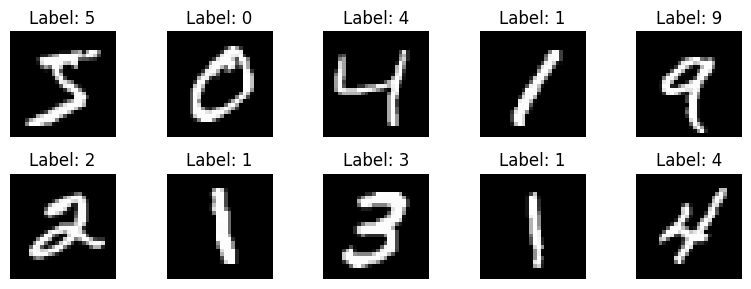

In [3]:
plt.figure(figsize=(8, 3))

for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(x_train[i].squeeze(), cmap="gray")
    plt.title(f"Label: {y_train[i]}")
    plt.axis("off")

plt.tight_layout()
plt.show()

In [4]:
def build_cnn(improved=False):
    model = models.Sequential()

    if not improved:
        # Basic CNN
        model.add(layers.Conv2D(
            32, (5, 5), activation="relu",
            input_shape=(28, 28, 1)
        ))
        model.add(layers.MaxPooling2D((2, 2)))
        model.add(layers.Conv2D(64, (5, 5), activation="relu"))
        model.add(layers.MaxPooling2D((2, 2)))
    else:
        # Experiment: more filters, ELU activation and dropout
        model.add(layers.Conv2D(
            32, (3, 3), activation="elu",
            input_shape=(28, 28, 1)
        ))
        model.add(layers.MaxPooling2D((2, 2)))
        model.add(layers.Conv2D(64, (3, 3), activation="elu"))
        model.add(layers.MaxPooling2D((2, 2)))
        model.add(layers.Dropout(0.25))

    model.add(layers.Flatten())
    model.add(layers.Dense(128, activation="relu"))
    model.add(layers.Dense(10, activation="softmax"))

    return model


 Basic CNN


/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 24, 24, 32)     │           832 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 12, 12, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 8, 8, 64)       │        51,264 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 4, 4, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 1024)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       131,200 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 184,586 (721.04 KB)

...

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_2 (Conv2D)               │ (None, 26, 26, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 13, 13, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 11, 11, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 5, 5, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 5, 5, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 1600)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │       204,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 225,034 (879.04 KB)

 Trainable params: 225,034 (879.04 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/5
422/422 ━━━━━━━━━━━━━━━━━━━━ 30s 69ms/step - accuracy: 0.9322 - loss: 0.2320 - val_accuracy: 0.9840 - val_loss: 0.0568
Epoch 2/5
422/422 ━━━━━━━━━━━━━━━━━━━━ 29s 69ms/step - accuracy: 0.9804 - loss: 0.0639 - val_accuracy: 0.9882 - val_loss: 0.0432
Epoch 3/5
422/422 ━━━━━━━━━━━━━━━━━━━━ 41s 68ms/step - accuracy: 0.9861 - loss: 0.0444 - val_accuracy: 0.9890 - val_loss: 0.0385
Epoch 4/5
422/422 ━━━━━━━━━━━━━━━━━━━━ 42s 69ms/step - accuracy: 0.9887 - loss: 0.0344 - val_accuracy: 0.9887 - val_loss: 0.0355
Epoch 5/5
422/422 ━━━━━━━━━━━━━━━━━━━━ 29s 69ms/step - accuracy: 0.9919 - loss: 0.0253 - val_accuracy: 0.9907 - val_loss: 0.0346


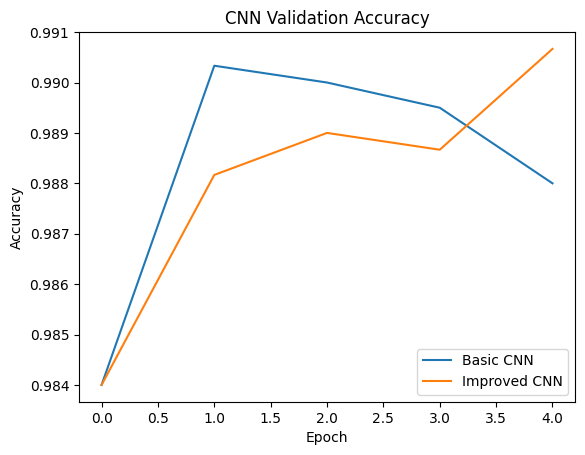

       Model     Loss  Test Accuracy
   Basic CNN 0.037748         0.9876
Improved CNN 0.028663         0.9906


In [5]:
results_cnn = []

for name, improved in [("Basic CNN", False), ("Improved CNN", True)]:
    model = build_cnn(improved)

    # Experiment with the loss function:
    # Integer labels use sparse categorical crossentropy.
    # One-hot labels use categorical crossentropy.
    if improved:
        y_train_cat = tf.keras.utils.to_categorical(y_train, 10)
        y_test_cat = tf.keras.utils.to_categorical(y_test, 10)
        loss = "categorical_crossentropy"
        train_labels = y_train_cat
        test_labels = y_test_cat
    else:
        loss = "sparse_categorical_crossentropy"
        train_labels = y_train
        test_labels = y_test

    model.compile(
        optimizer="adam",
        loss=loss,
        metrics=["accuracy"]
    )

    print("\n", name)
    model.summary()

    history = model.fit(
        x_train, train_labels,
        epochs=5,
        batch_size=128,
        validation_split=0.1,
        verbose=1
    )

    test_loss, test_acc = model.evaluate(
        x_test, test_labels, verbose=0
    )

    results_cnn.append({
        "Model": name,
        "Loss": test_loss,
        "Test Accuracy": test_acc
    })

    plt.plot(history.history["val_accuracy"], label=name)

plt.title("CNN Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.show()

print(pd.DataFrame(results_cnn).to_string(index=False))

In [6]:
print("""
LAB TASK 1: CNN ON MNIST

1. Preprocessing:
   Images were normalized to [0, 1] and reshaped to 28x28x1.

2. Architecture:
   Convolution, max pooling, flattening, and dense layers
   were used to classify 10 digit classes.

3. Experiments:
   The models use different kernel sizes, activations,
   dropout settings, and compatible loss functions.

4. Evaluation:
   Test loss and accuracy are displayed in the results table.
   The validation accuracy graph shows learning across epochs.

5. Observations:
   Compare both models' test accuracy. More filters or dropout
   may help, but improvements must be confirmed by the results.
""")


LAB TASK 1: CNN ON MNIST

1. Preprocessing:
   Images were normalized to [0, 1] and reshaped to 28x28x1.

2. Architecture:
   Convolution, max pooling, flattening, and dense layers
   were used to classify 10 digit classes.

3. Experiments:
   The models use different kernel sizes, activations,
   dropout settings, and compatible loss functions.

4. Evaluation:
   Test loss and accuracy are displayed in the results table.
   The validation accuracy graph shows learning across epochs.

5. Observations:
   Compare both models' test accuracy. More filters or dropout
   may help, but improvements must be confirmed by the results.



#Lab Task 2: Improving a neural network with Keras
For this task, we will use the Wine dataset from the UCI Machine Learning Repository, available through scikit-learn. The model will classify wine into three classes based on its measured chemical features.

In [7]:
# Load the UCI Wine dataset
wine = load_wine()
X = wine.data
y = wine.target

# Split data before scaling to avoid data leakage
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# Standardize features using training data only
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])
print("Number of features:", X_train.shape[1])
print("Number of classes:", len(np.unique(y)))

Training samples: 142
Testing samples: 36
Number of features: 13
Number of classes: 3


In [8]:
def build_wine_model(improved=False):
    model = models.Sequential()
    model.add(layers.Input(shape=(X_train.shape[1],)))

    if not improved:
        # Baseline model
        model.add(layers.Dense(16, activation="relu"))
    else:
        # Improved model: more neurons, regularization and dropout
        model.add(layers.Dense(
            64, activation="relu",
            kernel_regularizer=regularizers.l2(0.001)
        ))
        model.add(layers.Dropout(0.2))
        model.add(layers.Dense(32, activation="relu"))

    model.add(layers.Dense(3, activation="softmax"))
    return model

In [9]:
experiments = [
    # name, improved, optimizer, epochs, batch size
    ("Baseline Adam", False, "adam", 30, 16),
    ("Improved Adam", True, "adam", 50, 16),
    ("Improved RMSprop", True, "rmsprop", 50, 16),
    ("Improved SGD Momentum", True,
     tf.keras.optimizers.SGD(learning_rate=0.01, momentum=0.9),
     50, 16)
]

results_wine = []

for name, improved, optimizer, epochs, batch_size in experiments:
    model = build_wine_model(improved)

    model.compile(
        optimizer=optimizer,
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )

    print("\nTraining:", name)

    history = model.fit(
        X_train, y_train,
        epochs=epochs,
        batch_size=batch_size,
        validation_split=0.2,
        verbose=0
    )

    # Evaluate on unseen test data
    test_loss, test_acc = model.evaluate(
        X_test, y_test, verbose=0
    )

    results_wine.append({
        "Model": name,
        "Epochs": epochs,
        "Batch Size": batch_size,
        "Optimizer": name.split()[-1],
        "Test Loss": test_loss,
        "Test Accuracy": test_acc
    })

    print(f"Test accuracy: {test_acc:.4f}")

# Compare experimental results
wine_results = pd.DataFrame(results_wine)
print("\nWine Model Comparison:")
print(wine_results.round(4).to_string(index=False))


Training: Baseline Adam
Test accuracy: 0.9167

Training: Improved Adam
Test accuracy: 0.9722

Training: Improved RMSprop
Test accuracy: 0.9444

Training: Improved SGD Momentum
Test accuracy: 0.9722

Wine Model Comparison:
                Model  Epochs  Batch Size Optimizer  Test Loss  Test Accuracy
        Baseline Adam      30          16      Adam     0.2968         0.9167
        Improved Adam      50          16      Adam     0.0745         0.9722
     Improved RMSprop      50          16   RMSprop     0.1435         0.9444
Improved SGD Momentum      50          16  Momentum     0.0708         0.9722


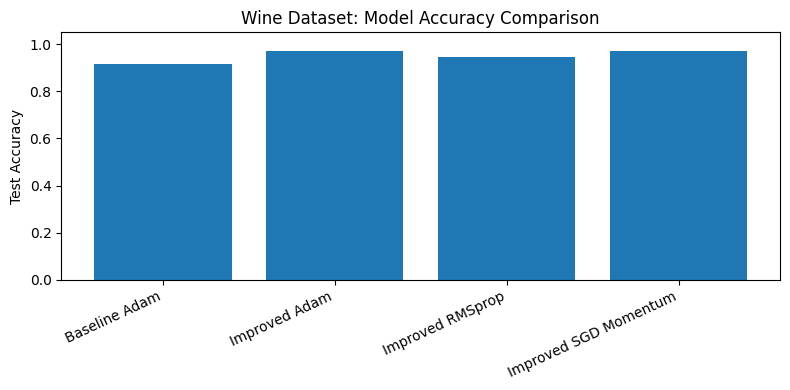

In [10]:
plt.figure(figsize=(8, 4))

plt.bar(
    wine_results["Model"],
    wine_results["Test Accuracy"]
)

plt.title("Wine Dataset: Model Accuracy Comparison")
plt.ylabel("Test Accuracy")
plt.xticks(rotation=25, ha="right")
plt.ylim(0, 1.05)
plt.tight_layout()
plt.show()

In [11]:
baseline_acc = wine_results.loc[
    wine_results["Model"] == "Baseline Adam",
    "Test Accuracy"
].iloc[0]

best_row = wine_results.loc[
    wine_results["Test Accuracy"].idxmax()
]



In [12]:
print(f"""
LAB TASK 2: NEURAL NETWORK PERFORMANCE IMPROVEMENT

1. Initial Performance:
   The baseline model used 16 neurons, Adam optimizer,
   30 epochs, and a batch size of 16.
   Test accuracy: {baseline_acc:.4f}

2. Techniques Applied:
   - Increased the number of neurons and hidden layers.
   - Applied L2 regularization and dropout.
   - Compared Adam, RMSprop, and SGD with momentum.
   - Experimented with different epoch counts.

3. Best Test Result:
   Model: {best_row['Model']}
   Test accuracy: {best_row['Test Accuracy']:.4f}
   Test loss: {best_row['Test Loss']:.4f}

4. Observations:
   The results show how architecture, regularization,
   and optimizers affect classification performance.
   The best observed test accuracy was achieved by
   {best_row['Model']}. Results can vary with data splits
   and random initialization.

5. Conclusion:
   Neural network performance depends on suitable
   hyperparameters and optimization techniques.
   The comparison helps identify a promising configuration.
""")


LAB TASK 2: NEURAL NETWORK PERFORMANCE IMPROVEMENT

1. Initial Performance:
   The baseline model used 16 neurons, Adam optimizer,
   30 epochs, and a batch size of 16.
   Test accuracy: 0.9167

2. Techniques Applied:
   - Increased the number of neurons and hidden layers.
   - Applied L2 regularization and dropout.
   - Compared Adam, RMSprop, and SGD with momentum.
   - Experimented with different epoch counts.

3. Best Test Result:
   Model: Improved Adam
   Test accuracy: 0.9722
   Test loss: 0.0745

4. Observations:
   The results show how architecture, regularization,
   and optimizers affect classification performance.
   The best observed test accuracy was achieved by
   Improved Adam. Results can vary with data splits
   and random initialization.

5. Conclusion:
   Neural network performance depends on suitable
   hyperparameters and optimization techniques.
   The comparison helps identify a promising configuration.

